In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/netflix_clean.csv", parse_dates=["date_added"])
print(df.shape)
df.dtypes

(8786, 17)


show_id                            str
type                               str
title                              str
director                           str
country                            str
date_added              datetime64[us]
release_year                     int64
rating                             str
duration                           str
listed_in                          str
duration_value                   int64
duration_unit                      str
added_before_release              bool
main_genre                         str
n_genres                         int64
year_added                       int64
month_added                        str
dtype: object

In [2]:
df[["release_year", "year_added", "n_genres"]].describe()

,release_year,year_added,n_genres
count,8786.000000,8786.000000,8786.000000
mean,2014.181766,2018.873663,2.194855
std,8.827137,1.573897,0.784193
min,1925.000000,2008.000000,1.000000
25%,2013.000000,2018.000000,2.000000
50%,2017.000000,2019.000000,2.000000
75%,2019.000000,2020.000000,3.000000
max,2021.000000,2021.000000,3.000000


In [4]:
df[["release_year", "year_added", "n_genres"]].describe()

,release_year,year_added,n_genres
count,8786.000000,8786.000000,8786.000000
mean,2014.181766,2018.873663,2.194855
std,8.827137,1.573897,0.784193
min,1925.000000,2008.000000,1.000000
25%,2013.000000,2018.000000,2.000000
50%,2017.000000,2019.000000,2.000000
75%,2019.000000,2020.000000,3.000000
max,2021.000000,2021.000000,3.000000


In [5]:
df[["type", "rating", "country", "main_genre"]].describe()

,type,rating,country,main_genre
count,8786,8786,8786,8786
unique,2,13,86,36
top,Movie,TV-MA,United States,Dramas
freq,6123,3204,3240,1597


In [6]:
df.groupby("duration_unit")["duration_value"].describe()

,count,mean,std,min,25%,50%,75%,max
duration_unit,,,,,,,,
Season,2663.0,1.752159,1.550844,1.0,1.0,1.0,2.0,17.0
min,6123.0,99.572595,28.282615,3.0,87.0,98.0,114.0,312.0


In [7]:
type_counts = df["type"].value_counts()
type_share = df["type"].value_counts(normalize=True).mul(100).round(1)
print(type_counts)
print(type_share)

type
Movie      6123
TV Show    2663
Name: count, dtype: int64
type
Movie      69.7
TV Show    30.3
Name: proportion, dtype: float64


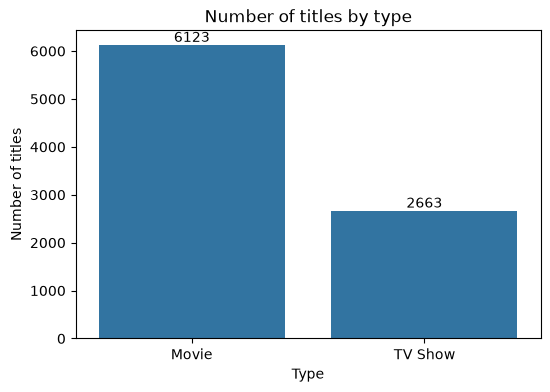

In [8]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="type", order=type_counts.index)
ax.bar_label(ax.containers[0])
plt.title("Number of titles by type")
plt.xlabel("Type")
plt.ylabel("Number of titles")
plt.show()

In [9]:
known = df[df["country"] != "Unknown"]
top_countries = known["country"].value_counts().head(10)
share = (top_countries / len(known) * 100).round(1)
print(len(known))
print(pd.DataFrame({"titles": top_countries, "share_%": share}))

8499
                titles  share_%
country                        
United States     3240     38.1
India             1056     12.4
United Kingdom     638      7.5
Pakistan           420      4.9
Canada             271      3.2
Japan              259      3.0
South Korea        214      2.5
France             213      2.5
Spain              182      2.1
Mexico             138      1.6


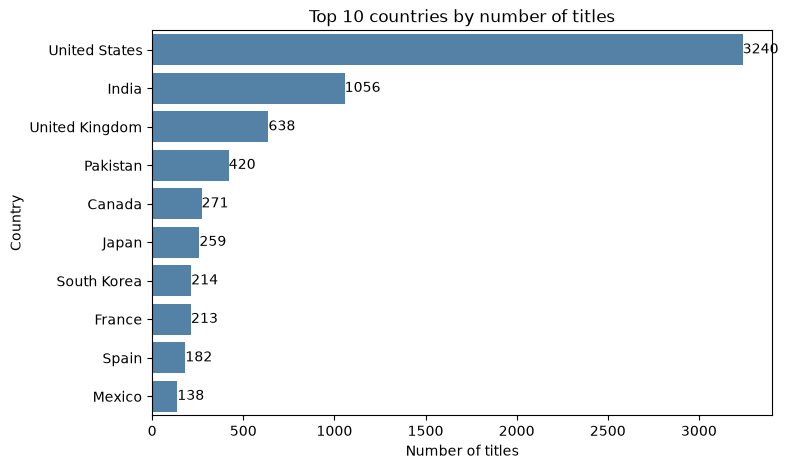

In [10]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=top_countries.values, y=top_countries.index, color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Top 10 countries by number of titles")
plt.xlabel("Number of titles")
plt.ylabel("Country")
plt.show()